In [3]:
import os
import pandas as pd
import numpy as np

In [4]:
in_dir = '../../results/03_kidney_atlas/03_run_cell2location'
out_dir = '../../results/03_kidney_atlas/04_select_markers'

os.makedirs(out_dir, exist_ok=True)

In [6]:
df = pd.read_csv(f'{in_dir}/subclass_l1/inf_aver.csv', index_col=0)    

In [7]:
df.head()

,ATL,CNT,DCT,DTL,EC,FIB,IC,IMM,NEU,PC,PEC,POD,PT,PapE,TAL,VSM/P
A1BG,0.076474,0.013540,0.001569,0.038672,0.002258,0.021858,0.017705,0.009474,0.051105,0.028503,0.047625,0.051604,0.003054,0.030759,0.005556,0.018382
A1BG-AS1,0.051257,0.018077,0.002034,0.036866,0.001520,0.026876,0.021888,0.022818,0.075050,0.016959,0.045594,0.074343,0.000449,0.033174,0.003734,0.025637
A1CF,0.003703,0.010593,0.012053,0.039933,0.007444,0.006180,0.010026,0.011256,0.031278,0.008759,0.030681,0.025985,0.371153,0.009020,0.005870,0.007096
A2M,0.057291,0.032186,0.051571,0.059049,1.231709,1.788672,0.050672,0.237073,0.324464,0.045119,0.038627,0.145021,0.023767,0.172512,0.051172,1.114644
A2M-AS1,0.001539,0.002159,0.004796,0.005916,0.001819,0.001807,0.001185,0.030835,0.020567,0.003268,0.001788,0.007217,0.004016,0.007300,0.003279,0.004202


In [8]:
# compute mean and std across rows
df['mean'] = df.mean(axis=1)
df['std'] = df.std(axis=1)

In [10]:
df.sort_values(['mean', 'std'], ascending=[False, True], inplace=True)

In [11]:
df

,ATL,CNT,DCT,DTL,EC,FIB,IC,IMM,NEU,PC,PEC,POD,PT,PapE,TAL,VSM/P,mean,std
MALAT1,204.726070,353.917900,404.439800,218.663270,111.076050,143.445400,351.319340,90.013150,41.947266,434.473270,164.481670,365.146550,184.437620,188.731920,248.305900,145.581450,228.169164,115.493190
NEAT1,13.369790,21.861723,19.974125,10.043172,13.071875,10.808407,16.763514,8.372929,3.754342,20.927282,12.647806,38.057670,27.537539,18.335180,14.083775,9.987011,16.224759,8.048435
PDE4D,11.896338,48.903023,20.935616,13.956709,5.410952,5.388540,29.322504,3.180563,2.366883,54.466007,8.474376,7.315015,16.095076,19.962173,7.971493,3.488390,16.195854,15.264733
MECOM,24.029076,38.538773,43.494670,7.140417,4.777144,1.844717,19.803043,1.860851,0.936519,48.168095,1.955520,2.658056,1.092740,24.886610,21.550960,4.445736,15.448933,15.900507
ZBTB20,14.489362,19.407362,12.656178,21.151821,8.956457,11.969812,31.938896,5.252921,6.681920,20.631779,17.391293,14.881954,17.388361,9.095486,12.299836,8.765189,14.559914,6.523680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
DAOA-AS1,0.000454,0.000237,0.000224,0.000165,0.000146,0.000294,0.000298,0.000194,0.021173,0.000144,0.000893,0.001387,0.000115,0.004404,0.000134,0.000564,0.001927,0.005074
AC002375.1,0.001015,0.000329,0.000685,0.000539,0.000501,0.000256,0.000272,0.000201,0.018743,0.001175,0.001181,0.000808,0.000223,0.004022,0.000145,0.000673,0.001923,0.004434
C11orf54,0.001474,0.000509,0.000408,0.000868,0.000114,0.000202,0.000595,0.000150,0.017041,0.000640,0.001496,0.001188,0.000086,0.004156,0.000293,0.000536,0.001860,0.004035
CTAGE15,0.000756,0.000722,0.000426,0.000927,0.000079,0.000086,0.000586,0.000128,0.017789,0.000437,0.001248,0.000708,0.000260,0.004898,0.000177,0.000375,0.001850,0.004262


In [18]:
# select top 300 genes variable genes
df_top300 = df.head(300)

Text(301.56186868686865, 0.5, 'Genes')

<Figure size 1000x800 with 0 Axes>

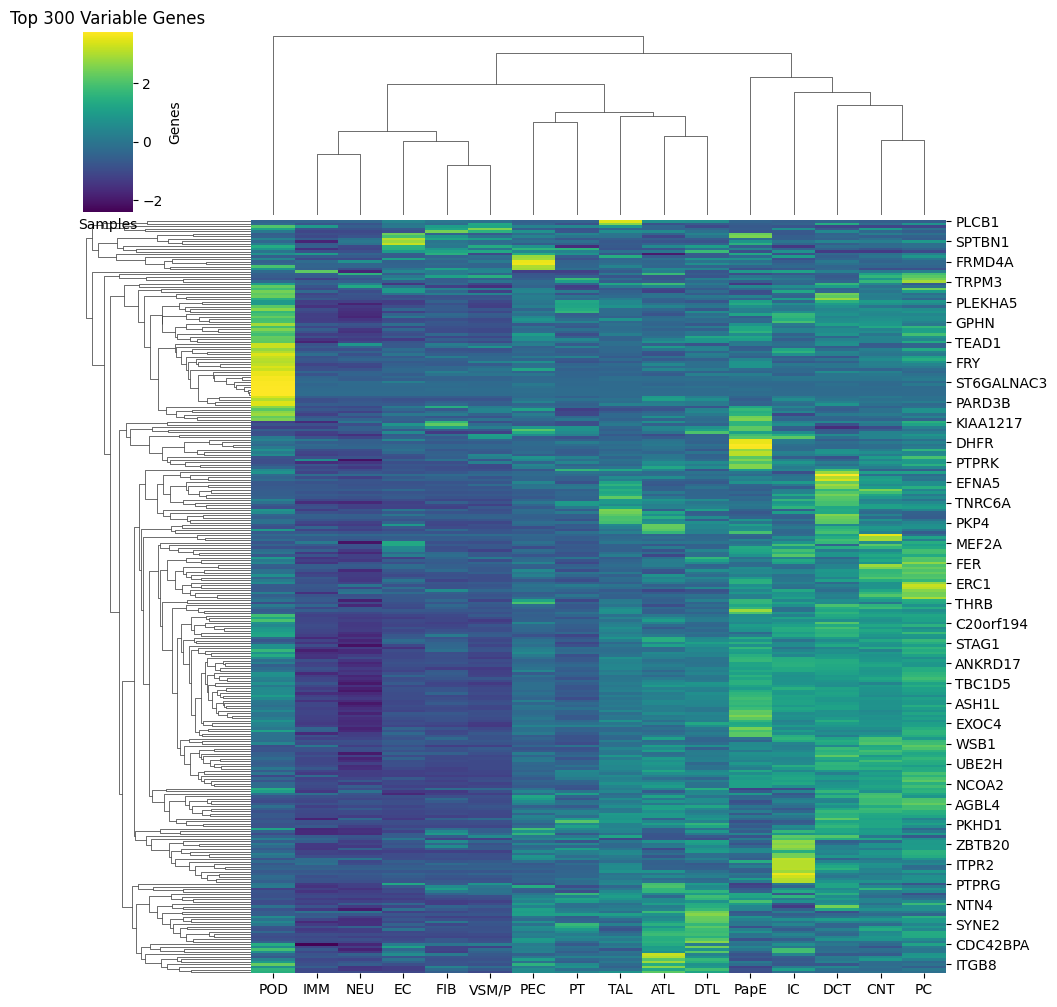

In [19]:
# plot with heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# first normalize the data for better visualization z-score normalization
df_top300.iloc[:, :-2] = (df_top300.iloc[:, :-2] - df_top300.iloc[:, :-2].mean(axis=1).values[:, None]) / df_top300.iloc[:, :-2].std(axis=1).values[:, None]

plt.figure(figsize=(10, 8))
sns.clustermap(df_top300.iloc[:, :-2], cmap='viridis')
plt.title('Top 300 Variable Genes')
plt.xlabel('Samples')
plt.ylabel('Genes')
# plt.savefig(f'{out_dir}/top300_variable_genes.png')